# Bank GoodCredit — Credit Risk Prediction

## 1. Project Overview

**Objective:** Predict customer credit risk using historical account information, credit enquiry data, and anonymized customer features.

**Business Goal:** Help the bank identify customers with a higher risk of bad credit history and make better-informed credit risk decisions.

**Target Variable:** `Bad_label`

- `0` — Good credit history
- `1` — Bad credit history (30+ days past due)

**Project Workflow:**
1. Data Collection and Database Connection
2. Data Understanding and Exploratory Data Analysis
3. Data Cleaning and Preprocessing
4. Feature Engineering and Feature Selection
5. Model Training
6. Model Evaluation using ROC-AUC, Gini and Decile Rank Ordering
7. Business Insights and Conclusions

## Import libraries

In [1]:

# Step 1: Import Required Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import mysql.connector

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

import warnings
warnings.filterwarnings("ignore")

# Display settings
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully!")


Libraries imported successfully!


## Connect to MySQL

In [ ]:
%pip install python-dotenv mysql-connector-python

In [ ]:
from pathlib import Path

env_path = Path.cwd() / ".env"
env_path.touch(exist_ok=True)

print("File location:", env_path.resolve())
print("File created:", env_path.exists())

In [ ]:
from pathlib import Path

env_path = Path.cwd() / ".env"

env_content = """DB_HOST=your_database_host
DB_PORT=3306
DB_USER=your_database_username
DB_PASSWORD=your_database_password
DB_NAME=project_banking
"""

env_path.write_text(env_content, encoding="utf-8")

print("Database configuration template saved!")

## Enter the database credentials securely

In [ ]:
from pathlib import Path
from getpass import getpass

env_path = Path.cwd() / ".env"

host = input("Enter database host: ").strip()
port = input("Enter database port [3306]: ").strip() or "3306"
user = input("Enter database username: ").strip()
password = getpass("Enter database password: ")
database = input("Enter database name: ").strip()

env_content = (
    f"DB_HOST={host}\n"
    f"DB_PORT={port}\n"
    f"DB_USER={user}\n"
    f"DB_PASSWORD={password}\n"
    f"DB_NAME={database}\n"
)

env_path.write_text(env_content, encoding="utf-8")

print("Database settings saved successfully.")

## Connect Jupyter to the MySQL database

In [ ]:
import os
from pathlib import Path
from dotenv import load_dotenv

env_path = Path.cwd() / ".env"
load_dotenv(env_path, override=True)

print("Notebook folder:", Path.cwd())
print("Environment file exists:", env_path.exists())

for key in ["DB_HOST", "DB_PORT", "DB_USER", "DB_NAME"]:
    print(f"{key} configured:", bool(os.getenv(key)))

print("Password configured:", bool(os.getenv("DB_PASSWORD")))

In [ ]:
try:
    connection = mysql.connector.connect(
        host=os.getenv("DB_HOST"),
        port=int(os.getenv("DB_PORT", "3306")),
        user=os.getenv("DB_USER"),
        password=os.getenv("DB_PASSWORD"),
        database=os.getenv("DB_NAME"),
        connection_timeout=10
    )
    print("MySQL connected successfully!")

except mysql.connector.Error as e:
    print("MySQL error code:", e.errno)
    print("MySQL error message:", e.msg)

## Check for accidental spaces in your settings

In [ ]:
import os

for key in ["DB_HOST", "DB_PORT", "DB_USER", "DB_NAME"]:
    value = os.getenv(key, "")
    print(f"{key}: {value!r}")

password = os.getenv("DB_PASSWORD", "")
print("Password has leading/trailing whitespace:",
      password != password.strip())
print("Password length:", len(password))

1. Project understanding
Objective: Predict whether a customer has good or bad credit history to help the bank identify potential credit-default risk.
- Bad_label = 0: Good credit history.
- Bad_label = 1: Bad credit history, associated with the 30+ days-past-due bucket.
- The project involves exploratory data analysis (EDA), feature engineering, model development, and model evaluation.
  
  2. Library setup
  We imported the Python libraries required for data handling, visualization, database connectivity, and machine learning.
- Pandas: Data manipulation and analysis.
- NumPy: Numerical calculations.
- Matplotlib and Seaborn: Data visualization.
- Scikit-learn: Machine learning and model evaluation.
  
  3. Database configuration
  We prepared the .env configuration and checked for accidental spaces in the settings.
Observation: The configuration checks were completed, but the MySQL connection returned error 1045 (access denied). This means database access was unsuccessful; it does not necessarily mean the settings were incorrect.

4. Decision to use demo data
Since the supplied database was inaccessible, we created synthetic data for learning and demonstrating the workflow.
The demo contains three tables:
- cust_demographics
- cust_account
- cust_enquiry
Important limitation: Synthetic data is not real bank customer data. Any patterns or model scores from it will be illustrative, not validated client results.

# Create Demo Dataset

In [9]:

# STEP 1: Create Synthetic Demo Data

import pandas as pd
import numpy as np

# Reproducible results
np.random.seed(42)

# Number of demo customers
n_customers = 1500

# Create an underlying risk factor for demonstration only
risk_factor = np.random.normal(0, 1, n_customers)

# Create the target: 0 = Good credit, 1 = Bad credit
bad_probability = 1 / (1 + np.exp(-(-1.5 + 1.1 * risk_factor)))
bad_label = np.random.binomial(1, bad_probability)

customer_ids = np.arange(100001, 100001 + n_customers)

# Table 1: Customer demographics
cust_demographics = pd.DataFrame({
    "customer_no": customer_ids,
    "entry_time": pd.Timestamp("2025-01-01")
                  + pd.to_timedelta(
                      np.random.randint(0, 365, n_customers),
                      unit="D"
                  ),
    "Bad_label": bad_label
})

# Create 79 anonymized demographic features
for i in range(1, 80):
    cust_demographics[f"feature_{i}"] = np.random.normal(
        0, 1, n_customers
    )

# Table 2: Customer account history
account_rows = []

for i, customer_id in enumerate(customer_ids):
    number_of_accounts = np.random.randint(1, 5)

    for _ in range(number_of_accounts):
        credit_limit = np.random.uniform(10000, 150000)
        utilization = np.clip(
            np.random.beta(2, 3) + 0.12 * risk_factor[i],
            0.02, 0.98
        )
        current_balance = credit_limit * utilization

        past_due = (
            current_balance * np.random.uniform(0.05, 0.30)
            if risk_factor[i] > 0.5
            else 0
        )

        account_rows.append({
            "customer_no": customer_id,
            "acct_type": np.random.choice(
                ["Credit Card", "Personal Loan", "Other"]
            ),
            "opened_dt": pd.Timestamp("2020-01-01")
                         + pd.to_timedelta(
                             np.random.randint(0, 1800), unit="D"
                         ),
            "last_paymt_dt": pd.Timestamp("2025-01-01")
                             + pd.to_timedelta(
                                 np.random.randint(0, 365), unit="D"
                             ),
            "high_credit_amt": credit_limit,
            "cur_balance_amt": current_balance,
            "amt_past_due": past_due,
            "creditlimit": credit_limit,
            "cashlimit": credit_limit * 0.3,
            "actualpaymentamount": max(
                0, current_balance * np.random.uniform(0.01, 0.25)
            )
        })

cust_account = pd.DataFrame(account_rows)

# Table 3: Customer credit enquiries
enquiry_rows = []

for i, customer_id in enumerate(customer_ids):
    number_of_enquiries = np.random.poisson(
        max(0.2, 2 + risk_factor[i])
    )

    for _ in range(number_of_enquiries):
        enquiry_rows.append({
            "customer_no": customer_id,
            "enquiry_dt": pd.Timestamp("2025-01-01")
                          + pd.to_timedelta(
                              np.random.randint(0, 365), unit="D"
                          ),
            "enq_purpose": np.random.choice(
                ["Credit Card", "Personal Loan", "Home Loan", "Other"]
            ),
            "enq_amt": np.random.uniform(5000, 100000)
        })

cust_enquiry = pd.DataFrame(enquiry_rows)

print("Demo data created successfully!")
print("Customers:", len(cust_demographics))
print("Account records:", len(cust_account))
print("Enquiry records:", len(cust_enquiry))
print("Demographic columns:", len(cust_demographics.columns))


Demo data created successfully!
Customers: 1500
Account records: 3714
Enquiry records: 3079
Demographic columns: 82


# Inspect the demo data

In [10]:

print("CUSTOMER DEMOGRAPHICS")
print("Shape:", cust_demographics.shape)
display(cust_demographics.head())

print("\nCUSTOMER ACCOUNT HISTORY")
print("Shape:", cust_account.shape)
display(cust_account.head())

print("\nCUSTOMER CREDIT ENQUIRIES")
print("Shape:", cust_enquiry.shape)
display(cust_enquiry.head())


CUSTOMER DEMOGRAPHICS
Shape: (1500, 82)


,customer_no,entry_time,Bad_label,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,...,feature_70,feature_71,feature_72,feature_73,feature_74,feature_75,feature_76,feature_77,feature_78,feature_79
0,100001,2025-10-03,0,-0.297482,-1.178923,-0.133003,0.947512,-0.375984,-0.697542,-1.070158,...,0.826028,0.490455,0.049443,-1.090916,2.051754,-0.758347,-0.430505,0.673835,-1.500166,0.873698
1,100002,2025-02-17,0,1.311984,-0.219669,-1.320892,0.674695,-0.561089,-1.618823,0.267136,...,-0.687062,-0.229919,1.887413,0.470668,-0.588290,1.487064,-2.372176,-1.212188,-0.333533,-1.713071
2,100003,2025-07-30,0,0.320786,0.609526,2.143007,-0.618365,-0.489414,-1.115126,0.318837,...,0.515994,1.057459,-0.660319,0.846961,-0.300240,1.395939,-0.885046,0.801083,-2.200999,-1.376100
3,100004,2025-12-09,1,0.194052,-1.555374,-0.469764,-0.794894,-2.745300,0.073219,-1.658775,...,-0.613931,0.346461,0.084517,-0.061012,-1.045334,-1.145411,1.748418,1.136627,0.635150,-0.551029
4,100005,2025-05-19,0,-1.270061,0.200845,0.158756,-2.072355,0.405035,-0.655328,0.759013,...,1.472842,-1.299557,1.001278,-1.211067,-2.029109,-0.229290,-1.929363,0.171276,-0.659497,0.497493



CUSTOMER ACCOUNT HISTORY
Shape: (3714, 10)


,customer_no,acct_type,opened_dt,last_paymt_dt,high_credit_amt,cur_balance_amt,amt_past_due,creditlimit,cashlimit,actualpaymentamount
0,100001,Personal Loan,2022-06-21,2025-01-02,68117.846700,40069.546727,0.00000,68117.846700,20435.354010,1647.780808
1,100001,Other,2022-04-22,2025-11-13,57619.110924,18450.119739,0.00000,57619.110924,17285.733277,3354.338801
2,100002,Credit Card,2021-07-08,2025-03-09,123153.648400,70850.223035,0.00000,123153.648400,36946.094520,2704.111604
3,100002,Other,2020-01-29,2025-05-18,99582.334150,52681.345870,0.00000,99582.334150,29874.700245,9832.916766
4,100003,Credit Card,2020-10-26,2025-12-25,43539.334420,10027.783071,2289.92014,43539.334420,13061.800326,1422.623393



CUSTOMER CREDIT ENQUIRIES
Shape: (3079, 4)


,customer_no,enquiry_dt,enq_purpose,enq_amt
0,100001,2025-06-12,Other,75204.825913
1,100001,2025-09-20,Home Loan,56881.054450
2,100001,2025-03-11,Other,22354.660821
3,100002,2025-07-29,Other,7320.001315
4,100003,2025-01-30,Other,95030.193522


### Observation: Initial Data Inspection

The three synthetic datasets were successfully created and displayed for initial inspection.

1. **Customer Demographics:** Contains customer identifiers, entry dates, anonymized demographic features (`feature_1` to `feature_79`), and the target variable `Bad_label`.
2. **Customer Account History:** Contains account-level information, including account type, opening date, credit limit, current balance, past-due amount, and payment amount.
3. **Customer Credit Enquiries:** Contains enquiry-level information, including customer identifiers, enquiry dates, enquiry purposes, and enquiry amounts.

The datasets contain information at different levels: customer-level, account-level, and enquiry-level. The `customer_no` column will help us connect records across the tables.



# Check data types and missing values

In [12]:
print("CUSTOMER DEMOGRAPHICS")
cust_demographics.info()

CUSTOMER DEMOGRAPHICS
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 82 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   customer_no  1500 non-null   int64         
 1   entry_time   1500 non-null   datetime64[ns]
 2   Bad_label    1500 non-null   int32         
 3   feature_1    1500 non-null   float64       
 4   feature_2    1500 non-null   float64       
 5   feature_3    1500 non-null   float64       
 6   feature_4    1500 non-null   float64       
 7   feature_5    1500 non-null   float64       
 8   feature_6    1500 non-null   float64       
 9   feature_7    1500 non-null   float64       
 10  feature_8    1500 non-null   float64       
 11  feature_9    1500 non-null   float64       
 12  feature_10   1500 non-null   float64       
 13  feature_11   1500 non-null   float64       
 14  feature_12   1500 non-null   float64       
 15  feature_13   1500 non-null   floa

In [13]:
print("\nMissing values in Customer Demographics:")
print(cust_demographics.isnull().sum().sum())


Missing values in Customer Demographics:
0


In [14]:
print("\nCUSTOMER ACCOUNT HISTORY")
cust_account.info()


CUSTOMER ACCOUNT HISTORY
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3714 entries, 0 to 3713
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   customer_no          3714 non-null   int64         
 1   acct_type            3714 non-null   object        
 2   opened_dt            3714 non-null   datetime64[ns]
 3   last_paymt_dt        3714 non-null   datetime64[ns]
 4   high_credit_amt      3714 non-null   float64       
 5   cur_balance_amt      3714 non-null   float64       
 6   amt_past_due         3714 non-null   float64       
 7   creditlimit          3714 non-null   float64       
 8   cashlimit            3714 non-null   float64       
 9   actualpaymentamount  3714 non-null   float64       
dtypes: datetime64[ns](2), float64(6), int64(1), object(1)
memory usage: 290.3+ KB


In [15]:
print("\nMissing values in Customer Account History:")
print(cust_account.isnull().sum().sum())


Missing values in Customer Account History:
0


In [16]:
print("\nCUSTOMER CREDIT ENQUIRIES")
cust_enquiry.info()


CUSTOMER CREDIT ENQUIRIES
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3079 entries, 0 to 3078
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   customer_no  3079 non-null   int64         
 1   enquiry_dt   3079 non-null   datetime64[ns]
 2   enq_purpose  3079 non-null   object        
 3   enq_amt      3079 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 96.3+ KB


In [17]:
print("\nMissing values in Customer Credit Enquiries:")
print(cust_enquiry.isnull().sum().sum())


Missing values in Customer Credit Enquiries:
0


### Observation: Data Types and Missing Values

The `info()` method was used to examine the column names, data types, and non-null record counts in all three datasets. The total number of missing values was also calculated for each dataset.

This step helps identify data-quality issues before performing exploratory data analysis (EDA) and feature engineering.

The results of this check will guide whether missing-value treatment or data-type conversion is required.

**Note:** The exact missing-value counts and data types should be interpreted from the notebook output. The datasets are synthetic and are being used for demonstration purposes.

# Check duplicate records

In [18]:
print("Customer Demographics duplicates:",
      cust_demographics.duplicated().sum())

print("Customer Account History duplicates:",
      cust_account.duplicated().sum())

print("Customer Credit Enquiries duplicates:",
      cust_enquiry.duplicated().sum())


Customer Demographics duplicates: 0
Customer Account History duplicates: 0
Customer Credit Enquiries duplicates: 0


### Observation: Duplicate Record Analysis

The `duplicated().sum()` method was used to identify exact duplicate rows in the customer demographics, account history, and credit enquiry datasets.

This check helps prevent repeated records from distorting the analysis. However, multiple account or enquiry records belonging to the same customer are valid and should not automatically be removed.

The duplicate counts should be reviewed before deciding whether any records require removal.

**Note:** These datasets are synthetic and intended for demonstration purposes.

## Understand our target variable

In [20]:

print("Target variable counts:")
print(cust_demographics["Bad_label"].value_counts().sort_index())

print("\nTarget variable percentages:")
print(
    (cust_demographics["Bad_label"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

print("\nTarget variable description:")
print(cust_demographics["Bad_label"].value_counts().rename({
    0: "Good Credit (0)",
    1: "Bad Credit (1)"
}))


Target variable counts:
Bad_label
0    1162
1     338
Name: count, dtype: int64

Target variable percentages:
Bad_label
0    77.47
1    22.53
Name: proportion, dtype: float64

Target variable description:
Bad_label
Good Credit (0)    1162
Bad Credit (1)      338
Name: count, dtype: int64


### Observation: Target Variable Analysis

The distribution of the target variable `Bad_label` was examined using value counts and percentage calculations.

- `Bad_label = 0` represents customers with good credit history.
- `Bad_label = 1` represents customers with bad credit history associated with the 30+ days-past-due bucket.

The class distribution helps us understand whether the synthetic dataset is balanced or imbalanced. This is important when selecting evaluation metrics and developing the credit risk classification model.

The actual class counts and percentages should be taken from the notebook output. Since this is synthetic data, the distribution does not represent the bank's real customer portfolio.

# Visualize the target variable

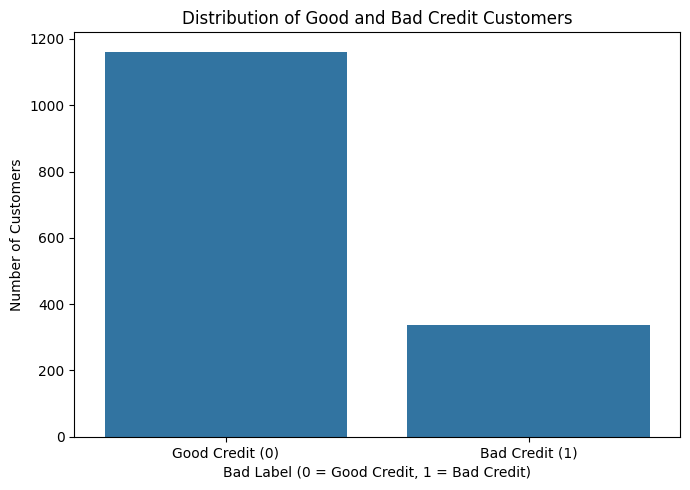

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(
    data=cust_demographics,
    x="Bad_label"
)

plt.title("Distribution of Good and Bad Credit Customers")
plt.xlabel("Bad Label (0 = Good Credit, 1 = Bad Credit)")
plt.ylabel("Number of Customers")
plt.xticks([0, 1], ["Good Credit (0)", "Bad Credit (1)"])

plt.tight_layout()
plt.show()


### Observation: Distribution of Good and Bad Credit Customers

A count plot was created to visualize the distribution of the target variable `Bad_label`.

The chart compares the number of customers with good credit history (`0`) against those with bad credit history (`1`).

This visualization helps assess class balance and provides an initial understanding of the classification problem. The class distribution should be considered when evaluating model performance, particularly the model's ability to identify bad-credit customers.

**Note:** The chart represents synthetic demo data and should not be interpreted as the actual credit-risk distribution of Bank GoodCredit customers.

# Explore numerical features

In [22]:
print("Summary Statistics:")
display(cust_demographics.describe().T)


Summary Statistics:


,count,mean,min,25%,50%,75%,max,std
customer_no,1500.0,100750.5,100001.0,100375.75,100750.5,101125.25,101500.0,433.157015
entry_time,1500,2025-07-04 16:59:31.200000,2025-01-01 00:00:00,2025-04-08 00:00:00,2025-07-07 00:00:00,2025-10-02 00:00:00,2025-12-31 00:00:00,NaN
Bad_label,1500.0,0.225333,0.0,0.0,0.0,0.0,1.0,0.417941
feature_1,1500.0,-0.039216,-3.176704,-0.705524,-0.015355,0.634238,3.243093,0.994267
feature_2,1500.0,-0.03776,-2.899514,-0.700489,-0.045189,0.644242,3.098299,1.000529
...,...,...,...,...,...,...,...,...
feature_75,1500.0,-0.012945,-3.433576,-0.707179,0.008587,0.64677,3.766234,1.022688
feature_76,1500.0,0.01774,-3.197455,-0.668929,0.018145,0.692134,3.228377,1.009121
feature_77,1500.0,0.000466,-3.701105,-0.700684,0.011879,0.661312,3.443736,1.015606
feature_78,1500.0,-0.018791,-3.153111,-0.700307,0.000698,0.646754,3.383526,1.025005


### Observation: Summary Statistics of Customer Demographics

The `describe().T` method was used to generate summary statistics for the numerical columns in the customer demographics dataset.

The output includes the mean, standard deviation, minimum, maximum, and quartiles for each numerical feature. These statistics help identify differences in feature scales and potential unusual values that may require further investigation.

Because the demographic features are synthetically generated, their statistical distributions are illustrative and do not describe actual bank customers.

The summary statistics will support subsequent data exploration and preprocessing decisions.

# Check the target variable's relationship with numerical features

In [23]:
feature_columns = [
    col for col in cust_demographics.columns
    if col.startswith("feature_")
]

group_comparison = cust_demographics.groupby(
    "Bad_label"
)[feature_columns].mean().T

group_comparison.columns = [
    "Good Credit (0)",
    "Bad Credit (1)"
]

group_comparison["Absolute Difference"] = (
    group_comparison["Good Credit (0)"]
    - group_comparison["Bad Credit (1)"]
).abs()

group_comparison = group_comparison.sort_values(
    "Absolute Difference",
    ascending=False
)

display(group_comparison.head(10))


,Good Credit (0),Bad Credit (1),Absolute Difference
feature_65,-0.040067,0.124723,0.164790
feature_20,0.050649,-0.106297,0.156946
feature_3,0.026602,-0.119574,0.146176
feature_67,-0.043213,0.095215,0.138428
feature_16,-0.039639,0.095110,0.134749
feature_46,0.017706,-0.102565,0.120271
feature_32,-0.021392,0.092375,0.113767
feature_28,-0.020357,0.091736,0.112093
feature_71,-0.008801,0.096024,0.104825
feature_33,0.035144,-0.069612,0.104756


### Observation: Comparison of Features by Credit Label

The mean values of the anonymized demographic features (`feature_1` to `feature_79`) were compared between good-credit customers (`Bad_label = 0`) and bad-credit customers (`Bad_label = 1`).

The absolute difference between the group means was calculated to identify features showing the largest differences between the two groups.

This analysis provides an initial view of how numerical features vary across the target classes. However, differences in group averages alone do not establish statistical significance or predictive importance.

**Limitation:** The demographic features were randomly generated for demonstration purposes. These comparisons cannot be treated as genuine credit-risk insights or evidence of real predictive relationships in Bank GoodCredit's customer data.

# Explore customer account history

In [24]:
print("Account types:")
display(cust_account["acct_type"].value_counts())

print("\nAccount numerical summary:")
display(
    cust_account[
        [
            "high_credit_amt",
            "cur_balance_amt",
            "amt_past_due",
            "creditlimit",
            "cashlimit",
            "actualpaymentamount"
        ]
    ].describe().T
)


Account types:


acct_type
Personal Loan    1253
Other            1240
Credit Card      1221
Name: count, dtype: int64


Account numerical summary:


,count,mean,std,min,25%,50%,75%,max
high_credit_amt,3714.0,80596.930118,40542.398731,10022.202231,45447.081700,80043.824389,116523.910898,149983.403228
cur_balance_amt,3714.0,32974.234131,26308.665472,200.444045,12172.698152,26474.262158,47744.546829,144972.032047
amt_past_due,3714.0,2439.587913,5022.572693,0.000000,0.000000,0.000000,2737.560743,35731.809941
creditlimit,3714.0,80596.930118,40542.398731,10022.202231,45447.081700,80043.824389,116523.910898,149983.403228
cashlimit,3714.0,24179.079035,12162.719619,3006.660669,13634.124510,24013.147317,34957.173270,44995.020968
actualpaymentamount,3714.0,4287.974599,4460.315746,7.120786,1049.216664,2752.835056,6097.883677,31117.870910


### Observation: Customer Account History Analysis

The account dataset was examined to understand the distribution of account types and the numerical characteristics of credit-related variables.

Summary statistics were generated for high-credit amounts, current balances, past-due amounts, credit limits, cash limits, and actual payment amounts.

These variables may help us derive useful credit-risk indicators, such as credit utilization and overdue-payment measures.

Because the data is synthetic, the observed distributions and account patterns are illustrative only and must not be interpreted as actual Bank GoodCredit customer behaviour.

# Explore customer credit enquiries

In [25]:
print("Enquiry purposes:")
display(cust_enquiry["enq_purpose"].value_counts())

print("\nEnquiry amount summary:")
display(cust_enquiry["enq_amt"].describe())

print("\nNumber of enquiries per customer:")
enquiries_per_customer = (
    cust_enquiry.groupby("customer_no")
    .size()
    .rename("enquiry_count")
)

display(enquiries_per_customer.describe())


Enquiry purposes:


enq_purpose
Other            793
Credit Card      789
Home Loan        767
Personal Loan    730
Name: count, dtype: int64


Enquiry amount summary:


count     3079.000000
mean     51818.975822
std      27702.993800
min       5078.983701
25%      27054.831922
50%      51399.523221
75%      75667.709740
max      99960.070685
Name: enq_amt, dtype: float64


Number of enquiries per customer:


count    1192.000000
mean        2.583054
std         1.575894
min         1.000000
25%         1.000000
50%         2.000000
75%         3.000000
max        11.000000
Name: enquiry_count, dtype: float64

### Observation: Customer Credit Enquiry Analysis

The credit enquiry dataset was analysed to understand the distribution of enquiry purposes, enquiry amounts, and the number of enquiries recorded per customer.

The `value_counts()` method was used to summarize enquiry purposes, `describe()` was used to examine enquiry amounts, and grouping by `customer_no` was used to calculate the number of enquiries per customer.

These variables may support the development of enquiry-related features, such as enquiry counts over specified time windows.

**Limitation:** The data is synthetic. Any observed enquiry patterns are illustrative and should not be interpreted as actual customer behaviour or validated indicators of credit risk.

# Visualize account types

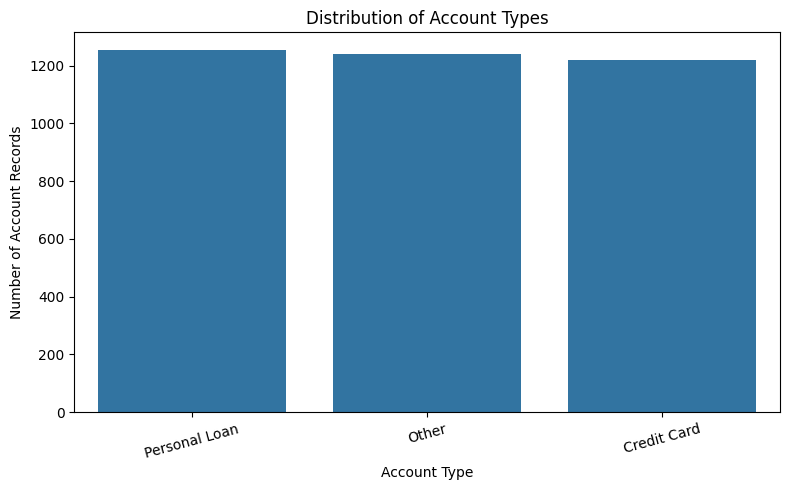

In [26]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=cust_account,
    x="acct_type",
    order=cust_account["acct_type"].value_counts().index
)

plt.title("Distribution of Account Types")
plt.xlabel("Account Type")
plt.ylabel("Number of Account Records")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()


Observation: Distribution of Account Types

A count plot was created to visualize the frequency of each account type in the customer account dataset.

The chart compares the number of records belonging to each account category. Since a customer may hold multiple accounts, the chart represents account records rather than unique customers.

This visualization helps summarize the composition of the demo account dataset and provides context for subsequent feature engineering.

Limitation: The account types and their distribution are based on synthetic data and do not represent the actual account portfolio of Bank GoodCredit.

# Visualize credit enquiry purposes

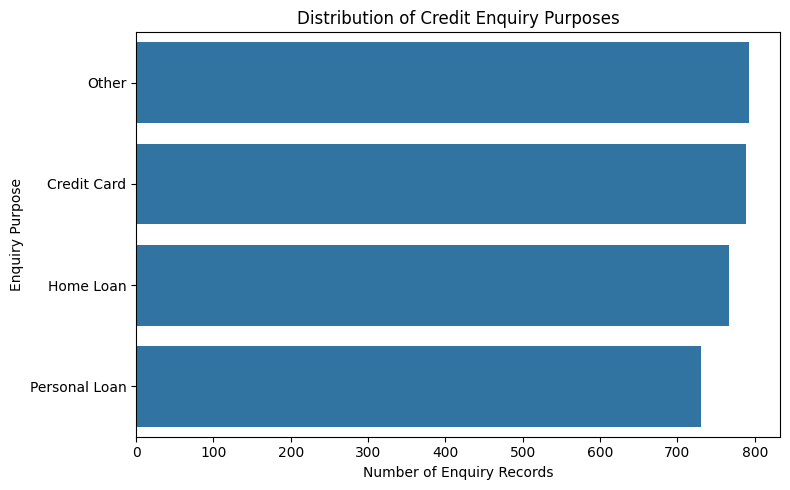

In [27]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=cust_enquiry,
    y="enq_purpose",
    order=cust_enquiry["enq_purpose"].value_counts().index
)

plt.title("Distribution of Credit Enquiry Purposes")
plt.xlabel("Number of Enquiry Records")
plt.ylabel("Enquiry Purpose")

plt.tight_layout()
plt.show()


### Observation: Distribution of Credit Enquiry Purposes

A horizontal count plot was created to examine the frequency of different credit enquiry purposes in the demo dataset.

The visualization allows the enquiry categories to be compared by their number of records and helps summarize the types of credit enquiries represented in the data.

This analysis may guide the creation of enquiry-related features, such as enquiry counts by purpose.

**Limitation:** The enquiry records are synthetic. The chart does not establish actual borrowing behaviour or credit-risk patterns among Bank GoodCredit customers.

# Feature engineering: Calculate credit utilization

In [28]:
cust_account["credit_utilization"] = np.where(
    cust_account["creditlimit"] > 0,
    cust_account["cur_balance_amt"] / cust_account["creditlimit"],
    np.nan
)

print("Credit utilization feature created.")

display(
    cust_account[
        [
            "customer_no",
            "cur_balance_amt",
            "creditlimit",
            "credit_utilization"
        ]
    ].head()
)

print("\nCredit utilization summary:")
display(cust_account["credit_utilization"].describe())


Credit utilization feature created.


,customer_no,cur_balance_amt,creditlimit,credit_utilization
0,100001,40069.546727,68117.846700,0.588239
1,100001,18450.119739,57619.110924,0.320208
2,100002,70850.223035,123153.648400,0.575299
3,100002,52681.345870,99582.334150,0.529023
4,100003,10027.783071,43539.334420,0.230315



Credit utilization summary:


count    3714.000000
mean        0.411219
std         0.228304
min         0.020000
25%         0.233651
50%         0.402049
75%         0.575916
max         0.980000
Name: credit_utilization, dtype: float64

### Observation: Credit Utilization Feature Engineering

A new feature, `credit_utilization`, was created by dividing the current account balance by the credit limit.

This feature represents the proportion of available credit currently being used. The calculation was performed only when the credit limit was positive to avoid division by zero.

Summary statistics were generated to examine the distribution of the calculated feature.

**Limitation:** The feature was derived from synthetic account data. Its values and distribution are illustrative and do not establish a real relationship with credit default.

# Create a past-due indicator

In [29]:
cust_account["has_past_due"] = (
    cust_account["amt_past_due"] > 0
).astype(int)

print("Past-due indicator created.")

print("\nPast-due indicator counts:")
display(cust_account["has_past_due"].value_counts().sort_index())

print("\nSample records:")
display(
    cust_account[
        ["customer_no", "amt_past_due", "has_past_due"]
    ].head(10)
)


Past-due indicator created.

Past-due indicator counts:


has_past_due
0    2511
1    1203
Name: count, dtype: int64


Sample records:


,customer_no,amt_past_due,has_past_due
0,100001,0.000000,0
1,100001,0.000000,0
2,100002,0.000000,0
3,100002,0.000000,0
4,100003,2289.920140,1
5,100003,1601.815662,1
6,100003,5072.542798,1
7,100004,7152.673778,1
8,100004,2963.979234,1
9,100004,4484.694908,1


### Observation: Past-Due Indicator Feature Engineering

A binary feature, `has_past_due`, was created from the `amt_past_due` column.

- `1` indicates that the account has a positive past-due amount.
- `0` indicates that the account has no positive past-due amount.

This feature provides a simple indicator of whether an account currently has an overdue balance. The original past-due amount is retained so that the magnitude of the overdue balance remains available for further analysis.

**Limitation:** This indicator reflects the synthetic account records and does not independently establish whether a customer will default.

# Aggregate account information by customer

In [30]:
customer_account_features = (
    cust_account.groupby("customer_no")
    .agg(
        number_of_accounts=("acct_type", "count"),
        avg_credit_utilization=("credit_utilization", "mean"),
        total_current_balance=("cur_balance_amt", "sum"),
        total_past_due=("amt_past_due", "sum"),
        accounts_with_past_due=("has_past_due", "sum")
    )
    .reset_index()
)

print("Customer-level account features created.")
print("Shape:", customer_account_features.shape)

display(customer_account_features.head())


Customer-level account features created.
Shape: (1500, 6)


,customer_no,number_of_accounts,avg_credit_utilization,total_current_balance,total_past_due,accounts_with_past_due
0,100001,2,0.454223,58519.666466,0.00000,0
1,100002,2,0.552161,123531.568905,0.00000,0
2,100003,3,0.406314,68248.508914,8964.27860,3
3,100004,3,0.576205,127542.134044,14601.34792,3
4,100005,3,0.347535,116900.326726,0.00000,0


# Create Customer-Level Enquiry Features

In [31]:
customer_enquiry_features = (
    cust_enquiry.groupby("customer_no")
    .agg(
        total_enquiries=("enq_purpose", "count"),
        avg_enquiry_amount=("enq_amt", "mean"),
        total_enquiry_amount=("enq_amt", "sum")
    )
    .reset_index()
)

print("Customer-level enquiry features created.")
print("Shape:", customer_enquiry_features.shape)

display(customer_enquiry_features.head())


Customer-level enquiry features created.
Shape: (1192, 4)


,customer_no,total_enquiries,avg_enquiry_amount,total_enquiry_amount
0,100001,3,51480.180395,154440.541185
1,100002,1,7320.001315,7320.001315
2,100003,4,49984.001096,199936.004386
3,100004,5,80526.019629,402630.098145
4,100005,2,20965.122318,41930.244636


# Merge all customer-level features

In [32]:
master_df = cust_demographics.merge(
    customer_account_features,
    on="customer_no",
    how="left"
)

master_df = master_df.merge(
    customer_enquiry_features,
    on="customer_no",
    how="left"
)

print("Master dataset created.")
print("Shape:", master_df.shape)
print("Unique customers:", master_df["customer_no"].nunique())

display(master_df.head())


Master dataset created.
Shape: (1500, 90)
Unique customers: 1500


,customer_no,entry_time,Bad_label,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,...,feature_78,feature_79,number_of_accounts,avg_credit_utilization,total_current_balance,total_past_due,accounts_with_past_due,total_enquiries,avg_enquiry_amount,total_enquiry_amount
0,100001,2025-10-03,0,-0.297482,-1.178923,-0.133003,0.947512,-0.375984,-0.697542,-1.070158,...,-1.500166,0.873698,2,0.454223,58519.666466,0.00000,0,3.0,51480.180395,154440.541185
1,100002,2025-02-17,0,1.311984,-0.219669,-1.320892,0.674695,-0.561089,-1.618823,0.267136,...,-0.333533,-1.713071,2,0.552161,123531.568905,0.00000,0,1.0,7320.001315,7320.001315
2,100003,2025-07-30,0,0.320786,0.609526,2.143007,-0.618365,-0.489414,-1.115126,0.318837,...,-2.200999,-1.376100,3,0.406314,68248.508914,8964.27860,3,4.0,49984.001096,199936.004386
3,100004,2025-12-09,1,0.194052,-1.555374,-0.469764,-0.794894,-2.745300,0.073219,-1.658775,...,0.635150,-0.551029,3,0.576205,127542.134044,14601.34792,3,5.0,80526.019629,402630.098145
4,100005,2025-05-19,0,-1.270061,0.200845,0.158756,-2.072355,0.405035,-0.655328,0.759013,...,-0.659497,0.497493,3,0.347535,116900.326726,0.00000,0,2.0,20965.122318,41930.244636


# Handle missing values in the master dataset

In [33]:
enquiry_columns = [
    "total_enquiries",
    "avg_enquiry_amount",
    "total_enquiry_amount"
]

master_df[enquiry_columns] = master_df[enquiry_columns].fillna(0)

print("Missing values handled for enquiry features.")

print("\nMissing values in enquiry features:")
display(master_df[enquiry_columns].isnull().sum())

print("\nMaster dataset shape:", master_df.shape)


Missing values handled for enquiry features.

Missing values in enquiry features:


total_enquiries         0
avg_enquiry_amount      0
total_enquiry_amount    0
dtype: int64


Master dataset shape: (1500, 90)


# Validate the master dataset

In [34]:
print("Total rows:", len(master_df))
print("Unique customers:", master_df["customer_no"].nunique())

print(
    "Duplicate customer IDs:",
    master_df["customer_no"].duplicated().sum()
)

print("\nMissing values across the master dataset:")
print("Total missing values:", master_df.isnull().sum().sum())

print("\nTarget variable present:", "Bad_label" in master_df.columns)


Total rows: 1500
Unique customers: 1500
Duplicate customer IDs: 0

Missing values across the master dataset:
Total missing values: 0

Target variable present: True


## Observation: Feature Engineering and Master Dataset Preparation (Steps 15–19)

### 1. Customer-Level Account Features

Account-level records were aggregated using `customer_no` to create customer-level features. These included the number of accounts, average credit utilization, total current balance, total past-due amount, and number of accounts with a positive past-due amount.

### 2. Customer-Level Enquiry Features

Credit enquiry records were aggregated by customer to calculate the total number of enquiries, average enquiry amount, and total enquiry amount. These features summarize enquiry activity for each customer represented in the enquiry dataset.

### 3. Master Dataset Creation

The customer demographics dataset was left-joined with the account and enquiry feature tables using `customer_no`. This produced a consolidated dataset containing customer information, the target variable `Bad_label`, and engineered account and enquiry features.

### 4. Missing Value Treatment

Missing values in the three enquiry summary columns were filled with zero. This represents the absence of recorded enquiry activity in the demo data. The average enquiry amount was also set to zero for customers without enquiry records as a demonstration convention.

### 5. Dataset Validation

The master dataset was checked for its total row count, number of unique customers, duplicate customer IDs, remaining missing values, and presence of the target variable. These checks help confirm whether the consolidated data is suitable for the next preparation stage.

### Conclusion

The account and enquiry datasets have been transformed into customer-level summaries and combined with the demographics dataset. The resulting master dataset provides the foundation for selecting model features and preparing the target variable.

**Limitation:** All records are synthetic and created for demonstration purposes. The engineered features and observed patterns have not been validated against actual Bank GoodCredit data.

# Select the model features

In [35]:

#  Prepare Features (X) and Target (y)

engineered_features = [
    "number_of_accounts",
    "avg_credit_utilization",
    "total_current_balance",
    "total_past_due",
    "accounts_with_past_due",
    "total_enquiries",
    "avg_enquiry_amount",
    "total_enquiry_amount"
]

demographic_features = [
    col for col in master_df.columns
    if col.startswith("feature_")
]

selected_features = demographic_features + engineered_features

X = master_df[selected_features].copy()
y = master_df["Bad_label"].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Number of selected features:", len(selected_features))

print("\nFirst five rows of X:")
display(X.head())

print("\nFirst five target values:")
display(y.head())


Feature matrix shape: (1500, 87)
Target shape: (1500,)
Number of selected features: 87

First five rows of X:


,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,...,feature_78,feature_79,number_of_accounts,avg_credit_utilization,total_current_balance,total_past_due,accounts_with_past_due,total_enquiries,avg_enquiry_amount,total_enquiry_amount
0,-0.297482,-1.178923,-0.133003,0.947512,-0.375984,-0.697542,-1.070158,-0.111354,-2.299456,0.962614,...,-1.500166,0.873698,2,0.454223,58519.666466,0.00000,0,3.0,51480.180395,154440.541185
1,1.311984,-0.219669,-1.320892,0.674695,-0.561089,-1.618823,0.267136,-0.210156,1.801045,0.042039,...,-0.333533,-1.713071,2,0.552161,123531.568905,0.00000,0,1.0,7320.001315,7320.001315
2,0.320786,0.609526,2.143007,-0.618365,-0.489414,-1.115126,0.318837,-0.950175,0.332346,0.907235,...,-2.200999,-1.376100,3,0.406314,68248.508914,8964.27860,3,4.0,49984.001096,199936.004386
3,0.194052,-1.555374,-0.469764,-0.794894,-2.745300,0.073219,-1.658775,0.269604,0.659402,-0.385933,...,0.635150,-0.551029,3,0.576205,127542.134044,14601.34792,3,5.0,80526.019629,402630.098145
4,-1.270061,0.200845,0.158756,-2.072355,0.405035,-0.655328,0.759013,2.262569,0.301001,-0.236818,...,-0.659497,0.497493,3,0.347535,116900.326726,0.00000,0,2.0,20965.122318,41930.244636



First five target values:


0    0
1    0
2    0
3    1
4    0
Name: Bad_label, dtype: int32

# Prepare the feature matrix

In [36]:

# Prepare the Feature Matrix

engineered_features = [
    "number_of_accounts",
    "avg_credit_utilization",
    "total_current_balance",
    "total_past_due",
    "accounts_with_past_due",
    "total_enquiries",
    "avg_enquiry_amount",
    "total_enquiry_amount"
]

demographic_features = [
    col for col in master_df.columns
    if col.startswith("feature_")
]

selected_features = demographic_features + engineered_features

X = master_df[selected_features].copy()
y = master_df["Bad_label"].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Total selected features:", len(selected_features))

print("\nFeature matrix preview:")
display(X.head())

print("\nTarget variable preview:")
display(y.head())


Feature matrix shape: (1500, 87)
Target shape: (1500,)
Total selected features: 87

Feature matrix preview:


,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,...,feature_78,feature_79,number_of_accounts,avg_credit_utilization,total_current_balance,total_past_due,accounts_with_past_due,total_enquiries,avg_enquiry_amount,total_enquiry_amount
0,-0.297482,-1.178923,-0.133003,0.947512,-0.375984,-0.697542,-1.070158,-0.111354,-2.299456,0.962614,...,-1.500166,0.873698,2,0.454223,58519.666466,0.00000,0,3.0,51480.180395,154440.541185
1,1.311984,-0.219669,-1.320892,0.674695,-0.561089,-1.618823,0.267136,-0.210156,1.801045,0.042039,...,-0.333533,-1.713071,2,0.552161,123531.568905,0.00000,0,1.0,7320.001315,7320.001315
2,0.320786,0.609526,2.143007,-0.618365,-0.489414,-1.115126,0.318837,-0.950175,0.332346,0.907235,...,-2.200999,-1.376100,3,0.406314,68248.508914,8964.27860,3,4.0,49984.001096,199936.004386
3,0.194052,-1.555374,-0.469764,-0.794894,-2.745300,0.073219,-1.658775,0.269604,0.659402,-0.385933,...,0.635150,-0.551029,3,0.576205,127542.134044,14601.34792,3,5.0,80526.019629,402630.098145
4,-1.270061,0.200845,0.158756,-2.072355,0.405035,-0.655328,0.759013,2.262569,0.301001,-0.236818,...,-0.659497,0.497493,3,0.347535,116900.326726,0.00000,0,2.0,20965.122318,41930.244636



Target variable preview:


0    0
1    0
2    0
3    1
4    0
Name: Bad_label, dtype: int32

# Validate the feature matrix

In [37]:
#Validate the Feature Matrix

print("Number of rows in X:", X.shape[0])
print("Number of rows in y:", y.shape[0])

print("\nMissing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

print("\nNon-numeric columns in X:")
display(X.select_dtypes(exclude="number").columns.tolist())

print("\nTarget classes:")
display(y.value_counts().sort_index())

assert X.shape[0] == y.shape[0], "X and y row counts do not match!"
assert X.select_dtypes(exclude="number").empty, "Some features are non-numeric!"

print("\nBasic feature matrix validation passed.")


Number of rows in X: 1500
Number of rows in y: 1500

Missing values in X: 0
Missing values in y: 0

Non-numeric columns in X:


[]


Target classes:


Bad_label
0    1162
1     338
Name: count, dtype: int64


Basic feature matrix validation passed.


# Split the data into training and testing sets

In [38]:
# Split Data into Training and Testing Sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True).sort_index().round(3))

print("\nTesting target distribution:")
display(y_test.value_counts(normalize=True).sort_index().round(3))


Training feature shape: (1200, 87)
Testing feature shape: (300, 87)

Training target shape: (1200,)
Testing target shape: (300,)

Training target distribution:


Bad_label
0    0.775
1    0.225
Name: proportion, dtype: float64


Testing target distribution:


Bad_label
0    0.773
1    0.227
Name: proportion, dtype: float64

# Standardize the numerical features

In [39]:
#  Standardize Numerical Features
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Original training shape:", X_train.shape)
print("Scaled training shape:", X_train_scaled.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Scaled testing shape:", X_test_scaled.shape)

print("\nMean of first 5 scaled training features:")
print(X_train_scaled[:, :5].mean(axis=0).round(3))

print("\nStandard deviation of first 5 scaled training features:")
print(X_train_scaled[:, :5].std(axis=0).round(3))


Original training shape: (1200, 87)
Scaled training shape: (1200, 87)

Original testing shape: (300, 87)
Scaled testing shape: (300, 87)

Mean of first 5 scaled training features:
[ 0.  0.  0. -0. -0.]

Standard deviation of first 5 scaled training features:
[1. 1. 1. 1. 1.]


## Train Logistic Regression

In [40]:
from sklearn.linear_model import LogisticRegression

# Create the model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
logistic_model.fit(X_train_scaled, y_train)

# Generate predictions
y_pred_logistic = logistic_model.predict(X_test_scaled)

# Predict probability of bad credit (class 1)
y_prob_logistic = logistic_model.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression model trained successfully!")
print("Number of training customers:", len(X_train))
print("Number of testing customers:", len(X_test))
print("Number of predictions generated:", len(y_pred_logistic))

print("\nFirst 10 actual labels:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted labels:")
print(y_pred_logistic[:10].tolist())

print("\nFirst 10 bad-credit probabilities:")
print(y_prob_logistic[:10].round(3))

Logistic Regression model trained successfully!
Number of training customers: 1200
Number of testing customers: 300
Number of predictions generated: 300

First 10 actual labels:
[0, 0, 0, 0, 0, 0, 1, 0, 0, 1]

First 10 predicted labels:
[0, 0, 0, 1, 0, 0, 1, 0, 0, 1]

First 10 bad-credit probabilities:
[0.064 0.056 0.31  0.614 0.121 0.415 0.664 0.466 0.459 0.724]


## Train a Decision Tree Model

In [41]:

from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree model
tree_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42,
    class_weight="balanced"
)

# Train the model
tree_model.fit(X_train, y_train)

# Generate predictions
y_pred_tree = tree_model.predict(X_test)

# Predict probability of bad credit (class 1)
y_prob_tree = tree_model.predict_proba(X_test)[:, 1]

print("Decision Tree model trained successfully!")

print("Number of predictions:", len(y_pred_tree))

print("\nFirst 10 actual labels:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted labels:")
print(y_pred_tree[:10].tolist())

print("\nFirst 10 bad-credit probabilities:")
print(y_prob_tree[:10].round(3))


Decision Tree model trained successfully!
Number of predictions: 300

First 10 actual labels:
[0, 0, 0, 0, 0, 0, 1, 0, 0, 1]

First 10 predicted labels:
[0, 0, 1, 0, 0, 1, 1, 0, 0, 1]

First 10 bad-credit probabilities:
[0.22  0.22  0.601 0.    0.22  0.765 0.835 0.    0.    0.835]


## Train the Random Forest model

In [42]:

from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

# Generate predictions
y_pred_rf = rf_model.predict(X_test)

# Predict probability of bad credit (class 1)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest model trained successfully!")
print("Number of predictions:", len(y_pred_rf))

print("\nFirst 10 actual labels:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted labels:")
print(y_pred_rf[:10].tolist())

print("\nFirst 10 bad-credit probabilities:")
print(y_prob_rf[:10].round(3))


Random Forest model trained successfully!
Number of predictions: 300

First 10 actual labels:
[0, 0, 0, 0, 0, 0, 1, 0, 0, 1]

First 10 predicted labels:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0]

First 10 bad-credit probabilities:
[0.211 0.134 0.301 0.397 0.171 0.433 0.458 0.48  0.34  0.473]


# Evaluate all three models

In [43]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

# Store predictions from all three models
model_predictions = {
    "Logistic Regression": y_pred_logistic,
    "Decision Tree": y_pred_tree,
    "Random Forest": y_pred_rf
}

# Calculate evaluation metrics
results = []

for model_name, predictions in model_predictions.items():
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

model_comparison = pd.DataFrame(results)

display(
    model_comparison.style.format({
        "Accuracy": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1 Score": "{:.3f}"
    })
)


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.767,0.462,0.176,0.255
1,Decision Tree,0.663,0.351,0.574,0.436
2,Random Forest,0.763,0.333,0.044,0.078


# Evaluate ROC-AUC and Gini

In [ ]:
# ROC-AUC: Measures how well the model distinguishes between the two classes.
# Gini: A credit-risk ranking metric calculated as \(Gini = 2 \times AUC - 1\).

In [44]:

from sklearn.metrics import roc_auc_score

# Store probabilities from all three models
model_probabilities = {
    "Logistic Regression": y_prob_logistic,
    "Decision Tree": y_prob_tree,
    "Random Forest": y_prob_rf
}

ranking_results = []

for model_name, probabilities in model_probabilities.items():
    auc = roc_auc_score(y_test, probabilities)
    gini = (2 * auc) - 1

    ranking_results.append({
        "Model": model_name,
        "ROC-AUC": auc,
        "Gini": gini
    })

ranking_comparison = pd.DataFrame(ranking_results)

display(
    ranking_comparison.style.format({
        "ROC-AUC": "{:.4f}",
        "Gini": "{:.4f}"
    })
)


,Model,ROC-AUC,Gini
0,Logistic Regression,0.6639,0.3278
1,Decision Tree,0.6619,0.3238
2,Random Forest,0.7069,0.4138


# Check the Confusion Matrix

In [45]:
from sklearn.metrics import confusion_matrix, classification_report

# Choose Random Forest for this detailed inspection
cm = confusion_matrix(y_test, y_pred_rf, labels=[0, 1])

print("Random Forest Confusion Matrix")
print("Rows = Actual labels; Columns = Predicted labels")
print("Label 0 = Good credit | Label 1 = Bad credit")
display(pd.DataFrame(
    cm,
    index=["Actual Good (0)", "Actual Bad (1)"],
    columns=["Predicted Good (0)", "Predicted Bad (1)"]
))

print("\nClassification Report")
print(classification_report(
    y_test,
    y_pred_rf,
    labels=[0, 1],
    target_names=["Good Credit (0)", "Bad Credit (1)"],
    zero_division=0
))


Random Forest Confusion Matrix
Rows = Actual labels; Columns = Predicted labels
Label 0 = Good credit | Label 1 = Bad credit


,Predicted Good (0),Predicted Bad (1)
Actual Good (0),226,6
Actual Bad (1),65,3



Classification Report
                 precision    recall  f1-score   support

Good Credit (0)       0.78      0.97      0.86       232
 Bad Credit (1)       0.33      0.04      0.08        68

       accuracy                           0.76       300
      macro avg       0.55      0.51      0.47       300
   weighted avg       0.68      0.76      0.69       300



# Identify the Most Important Features

Top 15 Most Important Features:


,Feature,Importance
0,total_past_due,0.049415
1,accounts_with_past_due,0.038566
2,avg_credit_utilization,0.032481
3,total_current_balance,0.022744
4,total_enquiry_amount,0.016599
5,feature_3,0.015988
6,avg_enquiry_amount,0.015197
7,feature_9,0.014732
8,feature_16,0.014302
9,feature_28,0.013522


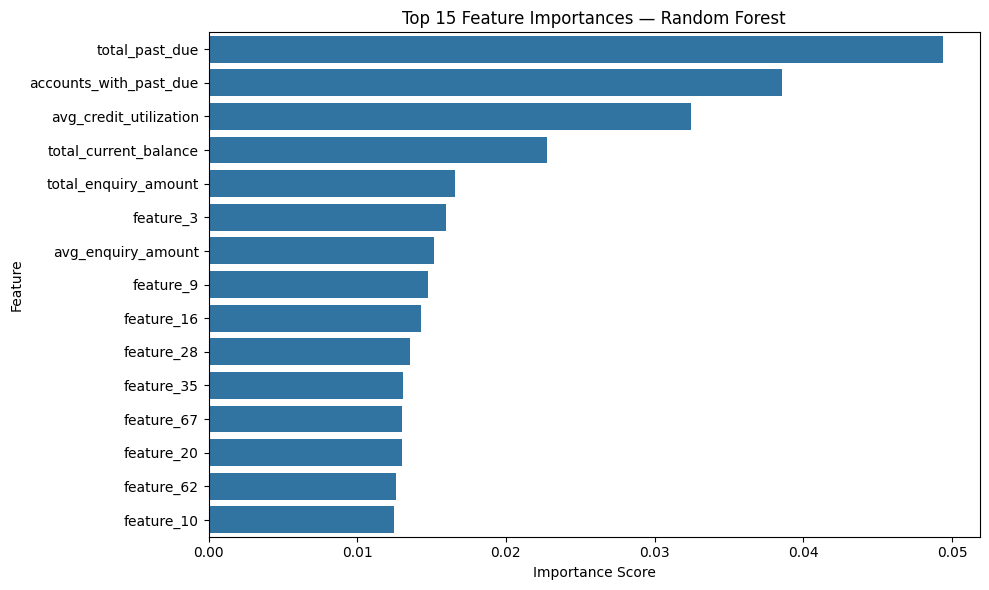

In [46]:
# Random Forest Feature Importance
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("Top 15 Most Important Features:")
display(feature_importance.head(15))

# Visualize the top 15 features
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importances — Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


# Create Decile-Based Rank Ordering

In [47]:
decile_df = pd.DataFrame({
    "Actual_Bad_Label": y_test.to_numpy(),
    "Predicted_Bad_Probability": y_prob_rf
})

# Sort from lowest to highest predicted risk
decile_df = decile_df.sort_values(
    "Predicted_Bad_Probability"
).reset_index(drop=True)

# Assign deciles: 1 = lowest risk, 10 = highest risk
decile_df["Decile"] = (
    pd.qcut(
        decile_df["Predicted_Bad_Probability"].rank(method="first"),
        q=10,
        labels=False
    ) + 1
)

decile_summary = (
    decile_df.groupby("Decile", observed=True)
    .agg(
        Customer_Count=("Actual_Bad_Label", "size"),
        Average_Predicted_Risk=("Predicted_Bad_Probability", "mean"),
        Actual_Bad_Customers=("Actual_Bad_Label", "sum"),
        Actual_Bad_Rate=("Actual_Bad_Label", "mean")
    )
    .reset_index()
)

decile_summary["Average_Predicted_Risk"] *= 100
decile_summary["Actual_Bad_Rate"] *= 100

print("Decile-Based Credit Risk Ranking")
display(
    decile_summary.style.format({
        "Average_Predicted_Risk": "{:.2f}%",
        "Actual_Bad_Rate": "{:.2f}%"
    })
)


Decile-Based Credit Risk Ranking


,Decile,Customer_Count,Average_Predicted_Risk,Actual_Bad_Customers,Actual_Bad_Rate
0,1,30,12.26%,2,6.67%
1,2,30,15.93%,4,13.33%
2,3,30,17.40%,4,13.33%
3,4,30,19.20%,4,13.33%
4,5,30,20.88%,6,20.00%
5,6,30,23.28%,2,6.67%
6,7,30,27.17%,7,23.33%
7,8,30,33.74%,11,36.67%
8,9,30,41.84%,13,43.33%
9,10,30,49.56%,15,50.00%


# Compare all models in one final table

In [48]:
final_comparison = model_comparison.merge(
    ranking_comparison,
    on="Model",
    how="left"
)

final_comparison = final_comparison.sort_values(
    by="ROC-AUC",
    ascending=False
).reset_index(drop=True)

print("FINAL MODEL PERFORMANCE COMPARISON")
display(
    final_comparison.style.format({
        "Accuracy": "{:.3f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1 Score": "{:.3f}",
        "ROC-AUC": "{:.4f}",
        "Gini": "{:.4f}"
    })
)

best_model_name = final_comparison.iloc[0]["Model"]
print("\nModel with the highest ROC-AUC:", best_model_name)


FINAL MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Gini
0,Random Forest,0.763,0.333,0.044,0.078,0.7069,0.4138
1,Logistic Regression,0.767,0.462,0.176,0.255,0.6639,0.3278
2,Decision Tree,0.663,0.351,0.574,0.436,0.6619,0.3238



Model with the highest ROC-AUC: Random Forest


# Visualize the model comparison

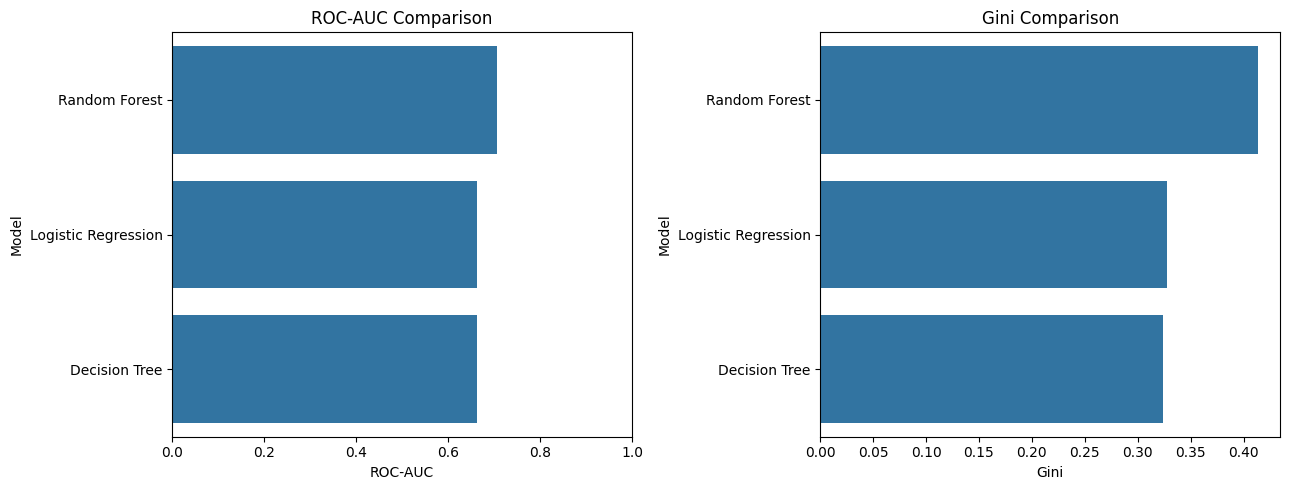

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=final_comparison,
    x="ROC-AUC",
    y="Model",
    ax=axes[0]
)
axes[0].set_title("ROC-AUC Comparison")
axes[0].set_xlim(0, 1)

sns.barplot(
    data=final_comparison,
    x="Gini",
    y="Model",
    ax=axes[1]
)
axes[1].set_title("Gini Comparison")

plt.tight_layout()
plt.show()


# Final business observations and recommendations

In [50]:
best_row = final_comparison.iloc[0]

print("=" * 60)
print("BANK GOODCREDIT — BUSINESS OBSERVATIONS")
print("=" * 60)

print(f"\nBest model by ROC-AUC: {best_row['Model']}")
print(f"ROC-AUC: {best_row['ROC-AUC']:.4f}")
print(f"Gini: {best_row['Gini']:.4f}")

print("\nMODEL COMPARISON:")
display(final_comparison)

print("\nDECILE RANKING:")
display(decile_summary)

lowest_decile_rate = decile_summary.iloc[0]["Actual_Bad_Rate"]
highest_decile_rate = decile_summary.iloc[-1]["Actual_Bad_Rate"]

print("\nRANKING CHECK:")
print(f"Decile 1 actual bad rate: {lowest_decile_rate:.2f}%")
print(f"Decile 10 actual bad rate: {highest_decile_rate:.2f}%")

if highest_decile_rate > lowest_decile_rate:
    print("The highest-risk decile has a higher observed bad rate.")
else:
    print("The highest-risk decile does not have a higher observed bad rate.")
    print("Review ranking performance before drawing conclusions.")

print("\nBUSINESS RECOMMENDATIONS:")
print("1. Validate the workflow using the bank's approved real customer data.")
print("2. Review recall and the cost of missed bad-credit customers.")
print("3. Monitor ranking quality across risk deciles.")
print("4. Review fairness, data leakage, and model explainability.")
print("5. Do not use this synthetic demo model for lending decisions.")


BANK GOODCREDIT — BUSINESS OBSERVATIONS

Best model by ROC-AUC: Random Forest
ROC-AUC: 0.7069
Gini: 0.4138

MODEL COMPARISON:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,Gini
0,Random Forest,0.763333,0.333333,0.044118,0.077922,0.706897,0.413793
1,Logistic Regression,0.766667,0.461538,0.176471,0.255319,0.663920,0.327840
2,Decision Tree,0.663333,0.351351,0.573529,0.435754,0.661923,0.323846



DECILE RANKING:


,Decile,Customer_Count,Average_Predicted_Risk,Actual_Bad_Customers,Actual_Bad_Rate
0,1,30,12.262926,2,6.666667
1,2,30,15.933170,4,13.333333
2,3,30,17.403436,4,13.333333
3,4,30,19.200309,4,13.333333
4,5,30,20.884245,6,20.000000
5,6,30,23.283179,2,6.666667
6,7,30,27.174495,7,23.333333
7,8,30,33.744516,11,36.666667
8,9,30,41.835121,13,43.333333
9,10,30,49.559899,15,50.000000



RANKING CHECK:
Decile 1 actual bad rate: 6.67%
Decile 10 actual bad rate: 50.00%
The highest-risk decile has a higher observed bad rate.

BUSINESS RECOMMENDATIONS:
1. Validate the workflow using the bank's approved real customer data.
2. Review recall and the cost of missed bad-credit customers.
3. Monitor ranking quality across risk deciles.
4. Review fairness, data leakage, and model explainability.
5. Do not use this synthetic demo model for lending decisions.


# Final project summary

In [51]:
print("=" * 65)
print("BANK GOODCREDIT — CREDIT RISK PREDICTION PROJECT")
print("=" * 65)

print("""
BUSINESS OBJECTIVE
Predict the probability that a customer belongs to the
bad-credit class (Bad_label = 1).

DATA PREPARATION
- Inspected customer demographics, account, and enquiry data.
- Created customer-level account and enquiry features.
- Merged the datasets into a master customer-level dataset.
- Prepared the feature matrix and target variable.
- Split the data into training and testing sets.

MODELS TRAINED
- Logistic Regression
- Decision Tree
- Random Forest

EVALUATION
- Accuracy, precision, recall, and F1-score
- ROC-AUC and Gini
- Confusion matrix
- Feature importance
- Decile-based risk ranking

IMPORTANT LIMITATION
This notebook currently uses synthetic demonstration data because
the real bank dataset was not available. Therefore, the scores,
feature importance, and decile results are illustrative only.

BEFORE REAL CLIENT DEPLOYMENT
- Validate on authorized real data.
- Check data quality and leakage.
- Tune models and validate on out-of-time data.
- Evaluate calibration, fairness, and business costs.
- Document monitoring and approval requirements.
""")

print("Project workflow summary completed.")
print("Use only validated real-data results for business decisions.")


BANK GOODCREDIT — CREDIT RISK PREDICTION PROJECT

BUSINESS OBJECTIVE
Predict the probability that a customer belongs to the
bad-credit class (Bad_label = 1).

DATA PREPARATION
- Inspected customer demographics, account, and enquiry data.
- Created customer-level account and enquiry features.
- Merged the datasets into a master customer-level dataset.
- Prepared the feature matrix and target variable.
- Split the data into training and testing sets.

MODELS TRAINED
- Logistic Regression
- Decision Tree
- Random Forest

EVALUATION
- Accuracy, precision, recall, and F1-score
- ROC-AUC and Gini
- Confusion matrix
- Feature importance
- Decile-based risk ranking

IMPORTANT LIMITATION
This notebook currently uses synthetic demonstration data because
the real bank dataset was not available. Therefore, the scores,
feature importance, and decile results are illustrative only.

BEFORE REAL CLIENT DEPLOYMENT
- Validate on authorized real data.
- Check data quality and leakage.
- Tune models and v